# Testing inference: how many neurons must the trigger recruit?

Companion to notebook 15: instead of truncating the trigger *in time*, this notebook
lesions it *in space* - the first `N_neuron` rows (neuron addresses) of the trigger are
silenced. It measures how much of the stored population code must be cued before the
network re-emits the complete memory: pattern completion along the *neuronal* axis.

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (weights from notebook 11, no retraining).
2. Single trial silencing `N_neuron // 32 = 32` trigger neurons -> F1 + raster.
3. Scan the number of silenced neurons from 0 to `N_neuron` in `N_scan=14` steps
      (`Params` default) x `N_cv=11` seeded repetitions (`get_scores_fraction`) ->
      `<datetag>_N_neurons.npz` (+ `.lock`); plot `fraction_target_score.pdf`.

### Main outputs
- cache `../cached_data/<datetag>_N_neurons.npz` (arrays `N_neurons`, `scores_np`);
- figures `fraction_target.pdf` (raster) and `fraction_target_score.pdf` (F1 vs number
     of inactive trigger neurons).

### Notes
- Lesion = zeroing `input_spikes[:, :N_neuron, N_pretime : N_pretime+num_delay]`, i.e.
     only within the trigger window, spontaneous pads untouched (the `*= 0` op).
- Losing 1/32 of the population costs little (f1 ~ 0.82 vs ~0.85 baseline): retrieval
     relies on a distributed, redundant code; check the scan for the percolation point.
- `scores_np` is `(N_scan, N_cv)`: F1 is the mean +/- s.d. over `N_cv` seeded cue
    realisations (`pattern_object(seed=...)` + `torch.manual_seed`, `seed += 1` per
    repetition, nb 20-style), scored against the clean `frozen_target`. The cache is
    saved after every lesion size, so an interrupted scan can resume.

<!-- MNESIS-annotated -->

In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, phi, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, trange
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout (frozen target reproduced from the same seed).

opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Retrieval from a partial trigger (spatial lesion)

Silencing `N_neuron // 32` neurons is a *hidden* ablation: those neurons' spikes are
removed from the cue only, but they still belong to the target and must be re-emitted
from the remaining 31/32 of the population.

In [3]:
# N_neuron//32 trigger neurons are silenced in the window [N_pretime, N_pretime+num_delay).

with torch.no_grad():
    target = hd.pattern_object()
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=target)
    input_spikes[:, :(opt.N_neuron//32), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]

    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.893	 recall = 0.734	 f1_score = 0.806 


### Raster of the lesioned-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the top of the green trigger band
is missing (lesioned neurons), yet red targets remain there.

File ../figures/fraction_target.pdf already exists. Skipping save.
File ../figures/fraction_target.png already exists. Skipping save.
File ../figures/fraction_target.svg already exists. Skipping save.


(torch.Size([16, 1024, 1100]), 146.0, 137.0)

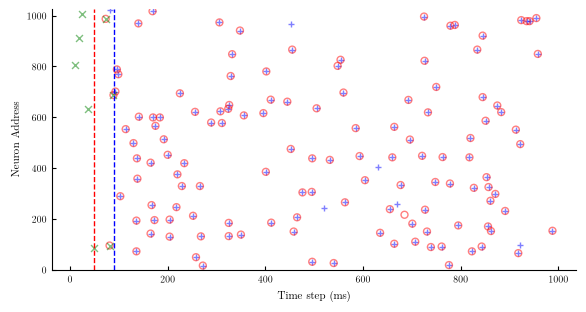

In [4]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'fraction_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1-score for different numbers of silenced trigger neurons

`get_scores_fraction`: `N_scan=36` values linspace(0, N_neuron) of silenced rows;
one trigger + forward pass + evoked-window `get_f1score` each. The curve locates the
*robustness threshold* - how large a lesion before the memory fails to ignite.
Cached as `<datetag>_N_neurons.npz` under the `.lock` protocol.

In [5]:
# One cue realisation per repetition (seeded nb 20-style); the spatial lesion is re-
# applied to each fresh cue and scored against the clean frozen_target; the cache is
# saved after every lesion size (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_fraction(N_scan=opt.N_scan, N_cv=opt.N_cv):
    N_neurons = np.linspace(0, hd.opt.N_neuron, N_scan, endpoint=True, dtype=int)
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_N_neuron in trange(N_scan):
        N_neuron = N_neurons[i_N_neuron]
        for i_cv in range(N_cv):
            with torch.no_grad():
                torch.manual_seed(seed)
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_)
                input_spikes[:, :(N_neuron), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_N_neuron, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, n_done=i_N_neuron + 1) # incremental save

    return N_neurons, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_N_neurons.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_neurons = data['N_neurons']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        N_neurons, scores_np = get_scores_fraction()
         ##################
        np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_N_neurons.npz


In [6]:
# sanity check that scan vectors are aligned.

N_neurons.shape, scores_np.shape

((14,), (14, 11))

File ../figures/fraction_target_score.pdf already exists. Skipping save.
File ../figures/fraction_target_score.png already exists. Skipping save.
File ../figures/fraction_target_score.svg already exists. Skipping save.


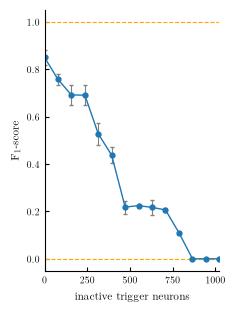

In [7]:
# $F_1$ vs number of inactive trigger neurons, mean +/- std over N_cv realisations;
# orange guides at 0 and 1.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_neurons[0], N_neurons[-1], 'orange', ls='--', lw=0.8)
    ax.errorbar(N_neurons, scores_np.mean(axis=1), yerr=scores_np.std(axis=1), fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"inactive trigger neurons")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_neurons[0], N_neurons[-1])
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'fraction_target_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
